# Phase 1: Data exploration
IML project, activity recognition from wearable sensor windows.

Goal -- know the shapes, class balance, channel scales, data quality,
train vs test differences, and whether the rows are ordered in some way.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "."

train = pd.read_csv(f"{DATA_DIR}/train.csv", low_memory=False)
test = pd.read_csv(f"{DATA_DIR}/test.csv", low_memory=False)
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

## 1. Shapes

In [2]:
print("train:", train.shape)
print("test :", test.shape)
print("sample submission:", sample_sub.shape)

print("train signal columns:", train.shape[1] - 2)
print("test signal columns :", test.shape[1] - 1)

train: (679, 5752)
test : (403, 5751)
sample submission: (403, 2)
train signal columns: 5750
test signal columns : 5750


## 2. Are all signal columns really numeric?
The DtypeWarning at load time hints that some columns may not be purely numeric,
so checking this before doing any maths on them.

In [3]:
signal_cols = [c for c in train.columns if c not in ("id", "target")]

print("same columns in test:", list(test.columns[1:]) == signal_cols)

obj_train = [c for c in signal_cols if train[c].dtype == "object"]
obj_test = [c for c in signal_cols if test[c].dtype == "object"]
print("object-type columns in train:", len(obj_train))
print("object-type columns in test :", len(obj_test))

for name, df, cols in [("train", train, obj_train), ("test", test, obj_test)]:
    for c in cols[:5]:
        as_num = pd.to_numeric(df[c], errors="coerce")
        bad = df.loc[as_num.isna() & df[c].notna(), c]
        print(name, c, "bad values:", bad.unique()[:5], "count:", len(bad))

same columns in test: True
object-type columns in train: 0
object-type columns in test : 0


## 3. Column naming and ordering
Columns are named t000_<channel> ... t249_<channel>. The reshape to
(windows, 250, 23) is only correct if the order is really time-major,
so checking that first.

In [4]:
pattern = re.compile(r"^t(\d+)_(.+)$")
parsed = [pattern.match(c) for c in signal_cols]
assert all(p is not None for p in parsed), "some column names don't match t###_<channel>"

time_idx = np.array([int(p.group(1)) for p in parsed])
channel_names = [p.group(2) for p in parsed]

n_channels = 23
n_steps = 250
channels = channel_names[:n_channels]
print("channels:")
for i, c in enumerate(channels):
    print(i, c)

same_channels = all(channel_names[t * n_channels:(t + 1) * n_channels] == channels
                    for t in range(n_steps))

time_major = np.array_equal(time_idx, np.repeat(np.arange(n_steps), n_channels))
print("\nsame channel order at every step:", same_channels)
print("time-major layout:", time_major)

channels:
0 chest_acc_x
1 chest_acc_y
2 chest_acc_z
3 chest_ecg_1
4 chest_ecg_2
5 ankle_acc_x
6 ankle_acc_y
7 ankle_acc_z
8 ankle_gyro_x
9 ankle_gyro_y
10 ankle_gyro_z
11 ankle_mag_x
12 ankle_mag_y
13 ankle_mag_z
14 arm_acc_x
15 arm_acc_y
16 arm_acc_z
17 arm_gyro_x
18 arm_gyro_y
19 arm_gyro_z
20 arm_mag_x
21 arm_mag_y
22 arm_mag_z

same channel order at every step: True
time-major layout: True


## 4. Reshape to (windows, time, channels)
Using errors="coerce" so any stray non-numeric value becomes NaN instead of
crashing. The NaNs get counted in the data section.

In [5]:
def to_3d(df):
    nums = df[signal_cols].apply(pd.to_numeric, errors="coerce")
    return nums.to_numpy(dtype=np.float64).reshape(-1, n_steps, n_channels)

X_train = to_3d(train)
X_test = to_3d(test)
y_train = train["target"].to_numpy()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (679, 250, 23)
X_test : (403, 250, 23)


## 5. Class distribution

target
cycling            67
jogging            66
lying              66
walking            63
running            61
standing           59
sitting            59
climbing_stairs    56
knees_bending      55
arm_elevation      55
waist_bends        53
jump_front_back    19
Name: count, dtype: int64

proportions:
target
cycling            0.099
jogging            0.097
lying              0.097
walking            0.093
running            0.090
standing           0.087
sitting            0.087
climbing_stairs    0.082
knees_bending      0.081
arm_elevation      0.081
waist_bends        0.078
jump_front_back    0.028
Name: count, dtype: float64

majority class baseline accuracy: 0.099


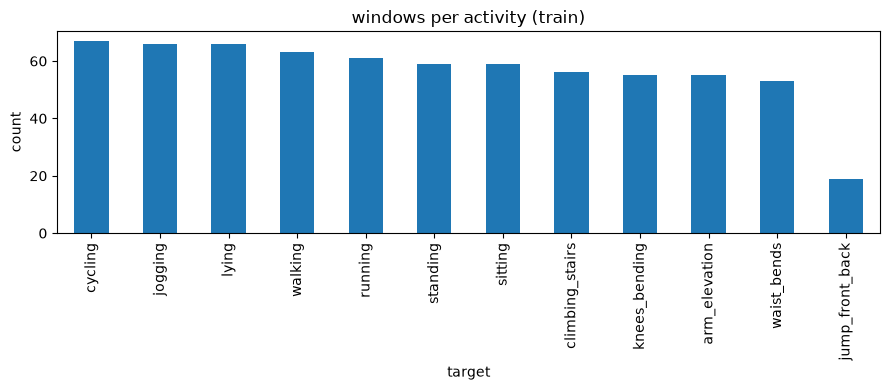

In [6]:
counts = train["target"].value_counts()
print(counts)
print("\nproportions:")
print((counts / counts.sum()).round(3))
print("\nmajority class baseline accuracy:", round(counts.max() / counts.sum(), 3))

plt.figure(figsize=(9, 4))
counts.plot(kind="bar")
plt.title("windows per activity (train)")
plt.ylabel("count")
plt.tight_layout()
plt.show()

## 6. Per-channel statistics
Flattening windows and time together and looking at each channel. The scales will
probably be very different, which matters later for scaling.

In [7]:
def channel_stats(X):
    flat = X.reshape(-1, X.shape[2])
    return pd.DataFrame({
        "mean": np.nanmean(flat, axis=0),
        "std": np.nanstd(flat, axis=0),
        "min": np.nanmin(flat, axis=0),
        "max": np.nanmax(flat, axis=0),
    }, index=channels)

pd.set_option("display.width", 200)
print("TRAIN")
print(channel_stats(X_train).round(3))
print("\nTEST")
print(channel_stats(X_test).round(3))

TRAIN
                 mean       std      min     max
chest_acc_x   494.694  2184.573  -67.010  9999.0
chest_acc_y   498.536  2176.606  -33.687  9999.0
chest_acc_z   501.230  2184.174  -48.111  9999.0
chest_ecg_1   503.698  2186.954  -10.568  9999.0
chest_ecg_2   508.219  2196.268  -10.273  9999.0
ankle_acc_x   506.146  2187.628  -47.910  9999.0
ankle_acc_y   491.707  2182.061  -66.352  9999.0
ankle_acc_z   503.464  2187.352  -70.270  9999.0
ankle_gyro_x  503.447  2186.094   -4.077  9999.0
ankle_gyro_y  508.844  2198.621   -5.081  9999.0
ankle_gyro_z  504.491  2188.876   -6.103  9999.0
ankle_mag_x   503.142  2191.195 -853.871  9999.0
ankle_mag_y   502.002  2190.820 -572.805  9999.0
ankle_mag_z   506.921  2193.889 -275.840  9999.0
arm_acc_x     497.998  2182.874  -68.176  9999.0
arm_acc_y     498.675  2189.512  -72.412  9999.0
arm_acc_z     508.107  2191.326  -46.846  9999.0
arm_gyro_x    506.162  2192.383   -5.792  9999.0
arm_gyro_y    503.361  2187.245   -6.014  9999.0
arm_gyro_z    

## 7. Data quality
Missing values, infinities, duplicates, constant channels and outliers.

In [8]:
print("NaN count   train:", int(np.isnan(X_train).sum()), " test:", int(np.isnan(X_test).sum()))
print("inf count   train:", int(np.isinf(X_train).sum()), " test:", int(np.isinf(X_test).sum()))
print("duplicate ids in train:", train["id"].duplicated().sum())
print("duplicate signal rows in train:", train[signal_cols].duplicated().sum())

#where are NaNs
nan_per_channel = np.isnan(X_train).sum(axis=(0, 1))
print("\nNaNs per channel (train):")
print(pd.Series(nan_per_channel, index=channels))

#channels that never change
flat_tr = X_train.reshape(-1, n_channels)
stds = np.nanstd(flat_tr, axis=0)
print("\nconstant channels:", [c for c, s in zip(channels, stds) if s == 0])

#columns that have same value in every window
nun = train[signal_cols].nunique()
print("constant raw columns:", int((nun <= 1).sum()))

#outliers
safe_std = np.where(stds == 0, 1, stds)
z = np.abs((flat_tr - np.nanmean(flat_tr, axis=0)) / safe_std)
print("\nshare of readings with |z| > 5:")
print(pd.Series((z > 5).mean(axis=0), index=channels).round(5))

NaN count   train: 516835  test: 0
inf count   train: 0  test: 0
duplicate ids in train: 44
duplicate signal rows in train: 44

NaNs per channel (train):
chest_acc_x     22416
chest_acc_y     22470
chest_acc_z     22400
chest_ecg_1     22474
chest_ecg_2     22511
ankle_acc_x     22332
ankle_acc_y     22426
ankle_acc_z     22571
ankle_gyro_x    22456
ankle_gyro_y    22534
ankle_gyro_z    22525
ankle_mag_x     22410
ankle_mag_y     22419
ankle_mag_z     22480
arm_acc_x       22574
arm_acc_y       22488
arm_acc_z       22506
arm_gyro_x      22468
arm_gyro_y      22422
arm_gyro_z      22603
arm_mag_x       22473
arm_mag_y       22417
arm_mag_z       22460
dtype: int64

constant channels: []
constant raw columns: 0

share of readings with |z| > 5:
chest_acc_x     0.0
chest_acc_y     0.0
chest_acc_z     0.0
chest_ecg_1     0.0
chest_ecg_2     0.0
ankle_acc_x     0.0
ankle_acc_y     0.0
ankle_acc_z     0.0
ankle_gyro_x    0.0
ankle_gyro_y    0.0
ankle_gyro_z    0.0
ankle_mag_x     0.0
ankle_m

## 8. Train vs test shift
Test subjects are different people, so checking whether the channels look different.
Mean shift is in units of the train std.

In [9]:
flat_te = X_test.reshape(-1, n_channels)
shift = pd.DataFrame({
    "mean_shift (train std units)": (np.nanmean(flat_te, axis=0) - np.nanmean(flat_tr, axis=0)) / safe_std,
    "std ratio (test/train)": np.nanstd(flat_te, axis=0) / safe_std,
}, index=channels)
print(shift.round(3))

              mean_shift (train std units)  std ratio (test/train)
chest_acc_x                         -0.230                   0.003
chest_acc_y                         -0.229                   0.001
chest_acc_z                         -0.230                   0.002
chest_ecg_1                         -0.230                   0.000
chest_ecg_2                         -0.231                   0.000
ankle_acc_x                         -0.231                   0.002
ankle_acc_y                         -0.229                   0.002
ankle_acc_z                         -0.231                   0.003
ankle_gyro_x                        -0.230                   0.000
ankle_gyro_y                        -0.232                   0.000
ankle_gyro_z                        -0.231                   0.000
ankle_mag_x                         -0.230                   0.034
ankle_mag_y                         -0.230                   0.022
ankle_mag_z                         -0.231                   0

## 9. Are the rows in some order?
This decides how we build validation in Phase 2. If rows are sorted by subject or
activity, neighbouring rows are very similar and normal shuffled k-fold would
look too optimistic.

In [10]:
print(train[["id", "target"]].head(15))
print()
print(test[["id"]].head(5))

changes = (train["target"].values[1:] != train["target"].values[:-1]).mean()
p = counts / counts.sum()
print("\nlabel change rate between adjacent rows:", round(changes, 3))
print("expected if rows were shuffled         :", round(1 - (p ** 2).sum(), 3))

          id           target
0   TR000349          cycling
1   TR000004  jump_front_back
2   TR000165         standing
3   TR000592          jogging
4   TR000392    knees_bending
5   TR000445      waist_bends
6   TR000266  jump_front_back
7   TR000227          sitting
8   TR000450          cycling
9   TR000318  climbing_stairs
10  TR000594          walking
11  TR000581    arm_elevation
12  TR000173          jogging
13  TR000069          walking
14  TR000579    knees_bending

         id
0  TE000001
1  TE000002
2  TE000003
3  TE000004
4  TE000005

label change rate between adjacent rows: 0.922
expected if rows were shuffled         : 0.913


## 10. A quick look at the signals
One window per activity, first channel only, just to see what the signals look like.

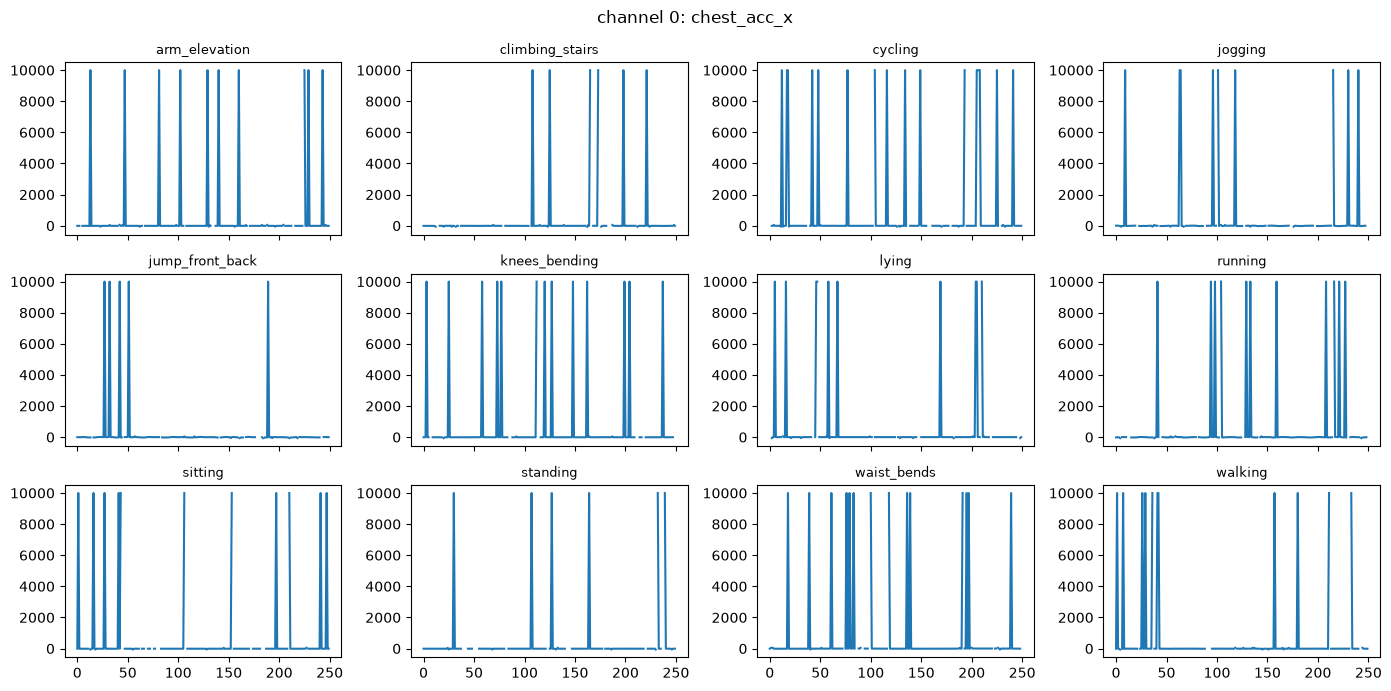

In [11]:
ch = 0   
fig, axes = plt.subplots(3, 4, figsize=(14, 7), sharex=True)
for ax, label in zip(axes.ravel(), sorted(counts.index)):
    idx = np.where(y_train == label)[0][0]
    ax.plot(X_train[idx, :, ch])
    ax.set_title(label, fontsize=9)
fig.suptitle(f"channel {ch}: {channels[ch]}")
plt.tight_layout()
plt.show()

# Notes

- shapes: train (679, 5752) = 5750 signals + id + target; test (403, 5751); sample submission (403, 2). Matches the doc.
- dtypes: 0 object columns; the DtypeWarning was just pandas chunk inference.
- layout: time-major confirmed; same 23 channels at every step (chest acc x/y/z + ecg 1/2; ankle acc, gyro, mag; arm acc, gyro, mag).
- classes: 12; cycling is the largest (67) -> majority baseline 0.099; jump_front_back is rare (19, 2.8%); the others have 53-67.
- scale: train channel stats are corrupted: mean ~500, std ~2185, max 9999.0 on every channel (9999 looks like a missing-value sentinel, ~5% of readings by my estimate).
- missing: 516,835 NaNs in train (~13.2% of 3,904,250 readings, ~22.4k per channel); test has 0 NaN; no infs.
- duplicates: 44 duplicate ids and 44 duplicate signal rows in train -> ~635 unique windows (to confirm).
- train/test shift: the -0.23 mean shift on every channel is an artifact of the 9999 values; recompute after cleaning.
- row order: label change rate 0.922 vs 0.913 expected -> shuffled; ids not yet checked for hidden order.
- signal plot: chest_acc_x is dominated by 9999 spikes; real signal not visible at that scale.
- decision: cleaning needed (9999 -> missing, interpolate per window, drop duplicates) before validation and features.